In [12]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from imblearn.over_sampling import SMOTE

In [13]:
# Load the CSV file into a DataFrame
df = pd.read_csv("/Users/abhisubrahmanyamkamuju/Desktop/ML_Project/analytical_base_table.csv")

# Display the first few rows of the DataFrame
print(df.head())

   CreditScore Geography  Gender  Age  Tenure    Balance  NumOfProducts  \
0          619    France  Female   42       2       0.00              1   
1          608     Spain  Female   41       1   83807.86              1   
2          502    France  Female   42       8  159660.80              3   
3          699    France  Female   39       1       0.00              2   
4          850     Spain  Female   43       2  125510.82              1   

   HasCrCard  IsActiveMember  EstimatedSalary  Exited  
0          1               1        101348.88       1  
1          0               1        112542.58       0  
2          1               0        113931.57       1  
3          0               0         93826.63       0  
4          1               1         79084.10       0  


In [14]:
# Separate dataframe into separate objects

# Object for target variable
target_variable = df.Exited

# Object for input features
input_features = df.drop(['Exited'], axis=1)

# Display shapes of features and target
print(input_features.shape, target_variable.shape)

(10000, 10) (10000,)


In [16]:
# List numerical features
numerical_columns = input_features.select_dtypes(include='number').columns.tolist()

# List categorical features
categorical_columns = input_features.select_dtypes(include='object').columns.tolist()


In [17]:
def class_count(data):
    counter = Counter(data)
    kv = [list(counter.keys()), list(counter.values())]
    data2 = pd.DataFrame(np.array(kv).T, columns=['Exited', 'Count'])
    data2['Count'] = data2['Count'].astype('int64')
    data2['%'] = round(data2['Count'] / data.shape[0] * 100, 2)
    return data2.sort_values('Count', ascending=False)

print(class_count(target_variable))

   Exited  Count      %
1       0   7963  79.63
0       1   2037  20.37


In [18]:
random_state = 10

# Split features (X) and target variable (y) into train and test sets
X_train, X_test, y_train, y_test = train_test_split(input_features, target_variable,
                                                    test_size=0.3,
                                                    random_state=random_state,
                                                    stratify=df.Exited)

# Print number of observations in X_train, X_test, y_train, and y_test
print(len(X_train), len(X_test), len(y_train), len(y_test))

# Display information about training data
print(X_train.info())

7000 3000 7000 3000
<class 'pandas.core.frame.DataFrame'>
Index: 7000 entries, 8061 to 4741
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   CreditScore      7000 non-null   int64  
 1   Geography        7000 non-null   object 
 2   Gender           7000 non-null   object 
 3   Age              7000 non-null   int64  
 4   Tenure           7000 non-null   int64  
 5   Balance          7000 non-null   float64
 6   NumOfProducts    7000 non-null   int64  
 7   HasCrCard        7000 non-null   int64  
 8   IsActiveMember   7000 non-null   int64  
 9   EstimatedSalary  7000 non-null   float64
dtypes: float64(2), int64(6), object(2)
memory usage: 601.6+ KB
None


In [19]:
# Define MinMaxScaler for numerical features
def min_max_scaler(X):
    min_values = np.min(X, axis=0)
    max_values = np.max(X, axis=0)
    return (X - min_values) / (max_values - min_values), min_values, max_values

X_train[numerical_columns], min_values, max_values = min_max_scaler(X_train[numerical_columns])
X_test[numerical_columns] = (X_test[numerical_columns] - min_values) / (max_values - min_values)

In [20]:
# Define OneHotEncoder for categorical features
def one_hot_encoder(X, cat_features):
    encoded_features = []
    for i in range(len(cat_features)):
        unique_values = np.unique(X[:, cat_features[i]])
        for value in unique_values:
            encoded_feature = (X[:, cat_features[i]] == value).astype(int)
            encoded_features.append(encoded_feature)
    return np.column_stack(encoded_features)

cat_features_indices = [X_train.columns.get_loc(col) for col in categorical_columns]

X_train_encoded = one_hot_encoder(X_train.values, cat_features_indices)
X_test_encoded = one_hot_encoder(X_test.values, cat_features_indices)


# Concatenate encoded categorical features with numerical features
X_train_processed = np.concatenate([X_train[numerical_columns].values, X_train_encoded], axis=1)
X_test_processed = np.concatenate([X_test[numerical_columns].values, X_test_encoded], axis=1)

In [21]:
def custom_smote(X_train, y_train, sampling_strategy=0.6, random_state=42):
    smote = SMOTE(sampling_strategy=sampling_strategy, random_state=random_state)
    X_resampled, y_resampled = smote.fit_resample(X_train, y_train)
    return X_resampled, y_resampled

# Example usage:
X_train_resampled, y_train_resampled = custom_smote(X_train_processed, y_train, sampling_strategy=0.8)

In [22]:
# Define Logistic Regression model
class LogisticRegression:
    def __init__(self, learning_rate=0.01, num_iterations=1000):
        self.learning_rate = learning_rate
        self.num_iterations = num_iterations
        self.weights = None
        self.bias = None
        
    def sigmoid(self, z):
        return 1 / (1 + np.exp(-z))
    
    def fit(self, X, y):
        m, n = X.shape
        self.weights = np.zeros(n)
        self.bias = 0
        
        for _ in range(self.num_iterations):
            linear_model = np.dot(X, self.weights) + self.bias
            y_predicted = self.sigmoid(linear_model)
            
            dw = (1 / m) * np.dot(X.T, (y_predicted - y))
            db = (1 / m) * np.sum(y_predicted - y)
            
            self.weights -= self.learning_rate * dw
            self.bias -= self.learning_rate * db
            
    def predict(self, X):
        linear_model = np.dot(X, self.weights) + self.bias
        y_predicted = self.sigmoid(linear_model)
        y_predicted_cls = [1 if i > 0.5 else 0 for i in y_predicted]
        return np.array(y_predicted_cls)

# Train the Logistic Regression model
model = LogisticRegression()
model.fit(X_train_resampled, y_train_resampled)

In [23]:
# Evaluate the model
def accuracy(y_true, y_pred):
    accuracy = np.sum(y_true == y_pred) / len(y_true)
    return accuracy

train_predictions = model.predict(X_train_processed)
test_predictions = model.predict(X_test_processed)

print(f"Training Data Score: {accuracy(y_train.values, train_predictions)}")
print(f"Testing Data Score: {accuracy(y_test.values, test_predictions)}")


Training Data Score: 0.7455714285714286
Testing Data Score: 0.733


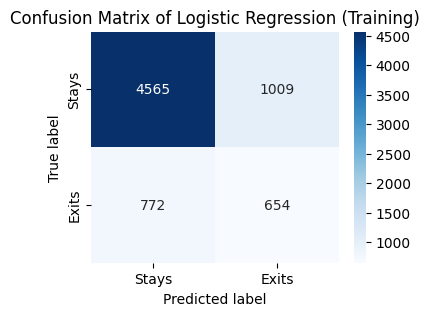

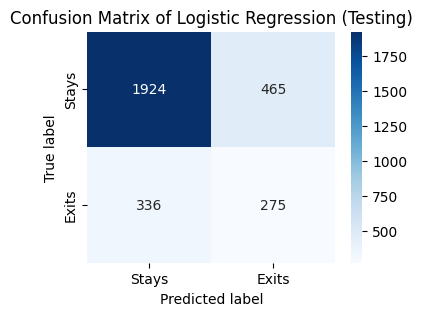

In [24]:
# Plotting the confusion matrix as a heatmap
def plot_confusion_matrix(cm, classes, title):
    plt.figure(figsize=(4, 3))
    sns.heatmap(cm, annot=True, cmap='Blues', fmt='g', 
                xticklabels=classes, 
                yticklabels=classes)
    plt.xlabel('Predicted label')
    plt.ylabel('True label')
    plt.title(title)
    plt.show()

# Assuming you already have defined cm and printed it
def confusion_matrix(y_true, y_pred):
    cm = np.zeros((2, 2))
    for i in range(len(y_true)):
        cm[y_true[i], y_pred[i]] += 1
    return cm

cm_train = confusion_matrix(y_train.values, train_predictions)
cm_test = confusion_matrix(y_test.values, test_predictions)

plot_confusion_matrix(cm_train, ['Stays', 'Exits'], 'Confusion Matrix of Logistic Regression (Training)')
plot_confusion_matrix(cm_test, ['Stays', 'Exits'], 'Confusion Matrix of Logistic Regression (Testing)')

In [25]:
# Display classification report
def classification_report(y_true, y_pred):
    true_positive = np.sum((y_true == 1) & (y_pred == 1))
    false_positive = np.sum((y_true == 0) & (y_pred == 1))
    true_negative = np.sum((y_true == 0) & (y_pred == 0))
    false_negative = np.sum((y_true == 1) & (y_pred == 0))
    
    precision = true_positive / (true_positive + false_positive)
    recall = true_positive / (true_positive + false_negative)
    f1_score = 2 * (precision * recall) / (precision + recall)
    
    print(f'Precision: {precision:.2f}')
    print(f'Recall: {recall:.2f}')
    print(f'F1 Score: {f1_score:.2f}')

print("Training Data Report:")
classification_report(y_train.values, train_predictions)
print("Testing Data Report:")
classification_report(y_test.values, test_predictions)


Training Data Report:
Precision: 0.39
Recall: 0.46
F1 Score: 0.42
Testing Data Report:
Precision: 0.37
Recall: 0.45
F1 Score: 0.41


In [26]:
# Display classification report
from sklearn.metrics import classification_report

def classification_report_custom(y_true, y_pred):
    report = classification_report(y_true, y_pred)
    print(report)

print("Training Data Report:")
classification_report_custom(y_train.values, train_predictions)
print("Testing Data Report:")
classification_report_custom(y_test.values, test_predictions)


Training Data Report:
              precision    recall  f1-score   support

           0       0.86      0.82      0.84      5574
           1       0.39      0.46      0.42      1426

    accuracy                           0.75      7000
   macro avg       0.62      0.64      0.63      7000
weighted avg       0.76      0.75      0.75      7000

Testing Data Report:
              precision    recall  f1-score   support

           0       0.85      0.81      0.83      2389
           1       0.37      0.45      0.41       611

    accuracy                           0.73      3000
   macro avg       0.61      0.63      0.62      3000
weighted avg       0.75      0.73      0.74      3000

